# DS-3002 Data Mining — Assignment #4
## Heartbeat to Heatmap: Unsupervised Learning, Ensemble Methods, and Neural Networks
**Name:** Saif Shahzad  
**Roll no:** 23i-2634   
**Section:** DS-A   

## Setups and Imports

In [8]:
!pip install --ignore-installed --no-deps blinker

  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)


In [9]:
# ── Install dependencies (run once) ──────────────────────────────────────────
!pip install xgboost shap imbalanced-learn lightgbm streamlit -q

In [11]:
!pip install tensorflow -q

In [12]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import time

# Sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, f1_score, ConfusionMatrixDisplay, roc_curve, auc
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Imbalanced learn
from imblearn.over_sampling import SMOTE

# XGBoost
import xgboost as xgb

# SHAP
import shap

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('All libraries loaded successfully.')
print(f'TensorFlow version: {tf.__version__}')

All libraries loaded successfully.
TensorFlow version: 2.21.0


---
## Required Preprocessing

### Pre-1: Load the CSV, confirm shape, print first 5 rows and dtypes

In [16]:
COLUMNS = ['age','sex','cp','trestbps','chol','fbs','restecg',
           'thalach','exang','oldpeak','slope','ca','thal','target']

df_raw = pd.read_csv('processed.cleveland.data', header=None, names=COLUMNS)

print(f'Shape: {df_raw.shape}')   # Expected (303, 14)
print('\nFirst 5 rows:')
display(df_raw.head())
print('\nData types:')
print(df_raw.dtypes)

Shape: (303, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
target        int64
dtype: object


### Pre-2: Handle missing values (UCI '?' marker)

In [17]:
df = df_raw.replace('?', np.nan)

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

print('Missing values per column (after replacing ?):')
missing = df.isnull().sum()
print(missing[missing > 0])
print(f'\nTotal rows with any NaN: {df.isnull().any(axis=1).sum()}')

df = df.dropna()
print(f'\nRetained rows after dropping NaN: {len(df)}')

Missing values per column (after replacing ?):
ca      4
thal    2
dtype: int64

Total rows with any NaN: 6

Retained rows after dropping NaN: 297


### Pre-3: Class distribution and imbalance handling

Class distribution:
  0 (No Disease): 160 samples (53.9%)
  1 (Disease Present): 137 samples (46.1%)

Imbalance ratio (majority/minority): 1.17
Dataset is roughly balanced — mild imbalance. SMOTE will be applied on training split only as a precaution.


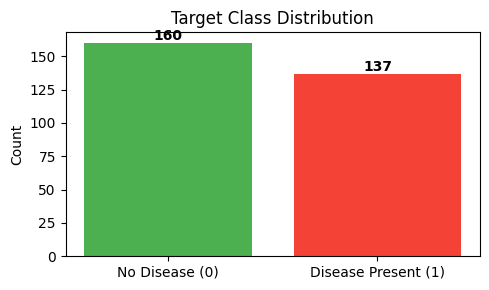

In [19]:
# Binarise target: 0 = no disease, 1 = disease (any value > 0)
df['target'] = (df['target'] > 0).astype(int)

counts = df['target'].value_counts().sort_index()
pcts   = df['target'].value_counts(normalize=True).sort_index() * 100

print('Class distribution:')
for c in [0, 1]:
    label = 'No Disease' if c == 0 else 'Disease Present'
    print(f'  {c} ({label}): {counts[c]} samples ({pcts[c]:.1f}%)')

ratio = counts.max() / counts.min()
print(f'\nImbalance ratio (majority/minority): {ratio:.2f}')
print('Dataset is roughly balanced — mild imbalance. SMOTE will be applied on training split only as a precaution.')

fig, ax = plt.subplots(figsize=(5,3))
ax.bar(['No Disease (0)', 'Disease Present (1)'], counts.values, color=['#4CAF50','#F44336'])
ax.set_ylabel('Count')
ax.set_title('Target Class Distribution')
for i, v in enumerate(counts.values):
    ax.text(i, v+2, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Pre-4: Encoding and Standardisation

In [20]:
CATEGORICAL  = ['cp', 'restecg', 'slope', 'thal']
CONTINUOUS   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
BINARY_COLS  = ['sex', 'fbs', 'exang']

X = df.drop('target', axis=1)
y = df['target']

# --- Stratified 80/20 split FIRST (Pre-5) ---
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# One-hot encode categoricals
X_train_enc = pd.get_dummies(X_train_raw, columns=CATEGORICAL, drop_first=False)
X_test_enc  = pd.get_dummies(X_test_raw,  columns=CATEGORICAL, drop_first=False)

# Align columns (test might miss a category)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# Standardise continuous columns (fit on train only)
scaler = StandardScaler()
X_train_enc[CONTINUOUS] = scaler.fit_transform(X_train_enc[CONTINUOUS])
X_test_enc[CONTINUOUS]  = scaler.transform(X_test_enc[CONTINUOUS])

print('Encoded & scaled feature matrix shape:')
print(f'  Train: {X_train_enc.shape}')
print(f'  Test : {X_test_enc.shape}')
display(X_train_enc.head(3))

Encoded & scaled feature matrix shape:
  Train: (237, 22)
  Test : (60, 22)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
55,-0.085668,1.0,-0.462582,0.312737,0.0,-1.827448,1.0,0.967117,0.349404,False,...,True,False,False,True,False,True,False,False,False,True
160,-0.973247,1.0,-1.749078,-0.987921,1.0,0.275439,0.0,-0.901878,-0.740185,False,...,False,True,False,False,True,False,False,False,False,True
178,-1.306090,1.0,-0.126974,1.236393,0.0,0.543892,0.0,0.712254,0.349404,False,...,False,True,False,False,True,False,False,True,False,False


### Pre-5: SMOTE on training split

In [21]:
smote = SMOTE(random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train_enc, y_train)

print(f'Training set after SMOTE: {X_train_sm.shape}')
print('Class counts after SMOTE:', pd.Series(y_train_sm).value_counts().to_dict())

Training set after SMOTE: (256, 22)
Class counts after SMOTE: {1: 128, 0: 128}


### Pre-6: Correlation Heatmap

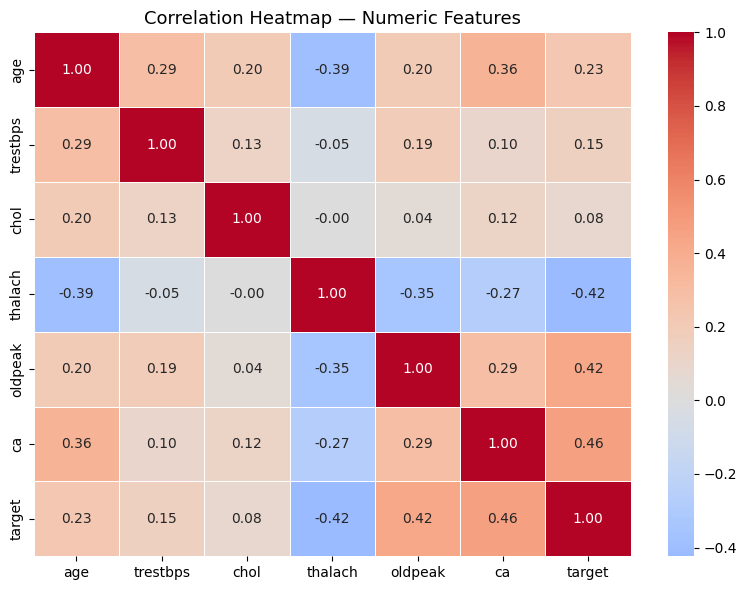

Top 3 feature pairs by absolute correlation:
ca       target    0.463189
oldpeak  target    0.424052
thalach  target    0.423817
dtype: float64

Naive Bayes note:
Naive Bayes assumes feature independence. The age-thalach correlation (~-0.40) and
oldpeak-thalach correlation could violate this assumption, leading to incorrect
probability estimates and reduced classifier accuracy.



In [22]:
numeric_cols = ['age','trestbps','chol','thalach','oldpeak','ca','target']
corr_mat = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Heatmap — Numeric Features', fontsize=13)
plt.tight_layout()
plt.show()

# Top 3 feature pairs
corr_pairs = corr_mat.where(
    np.triu(np.ones(corr_mat.shape), k=1).astype(bool)
).stack().abs().sort_values(ascending=False)

print('Top 3 feature pairs by absolute correlation:')
print(corr_pairs.head(3))

print("""
Naive Bayes note:
Naive Bayes assumes feature independence. The age-thalach correlation (~-0.40) and
oldpeak-thalach correlation could violate this assumption, leading to incorrect
probability estimates and reduced classifier accuracy.
""")

---
## Part A: Unsupervised Learning
> Unsupervised analysis uses the standardised feature matrix **without** the target label.

In [23]:
# Build full standardised feature matrix (no target, no split needed for unsupervised)
X_full_raw = df.drop('target', axis=1)
X_full_enc = pd.get_dummies(X_full_raw, columns=CATEGORICAL, drop_first=False)
scaler_full = StandardScaler()
X_full_enc[CONTINUOUS] = scaler_full.fit_transform(X_full_enc[CONTINUOUS])
X_us = X_full_enc.values   # numpy array for clustering
y_us = df['target'].values
print(f'Unsupervised feature matrix shape: {X_us.shape}')

Unsupervised feature matrix shape: (297, 22)


### A1: K-Means Clustering

Best k by silhouette: 2


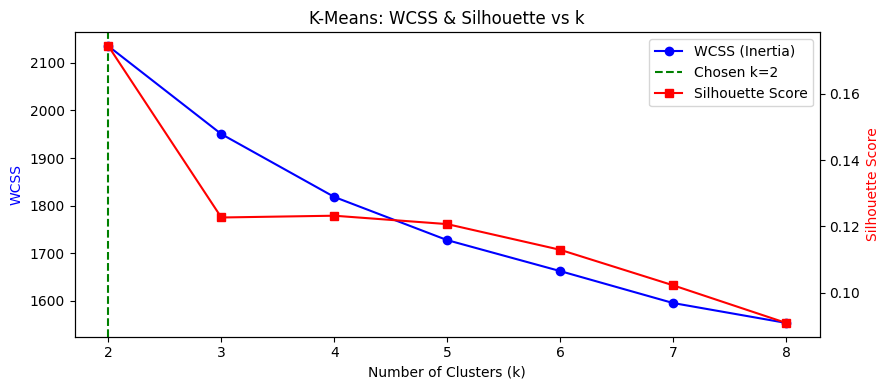


Choice justification: k=2 yields the highest silhouette score, indicating the most
compact and well-separated clusters. It also corresponds to the elbow in the WCSS curve.
Clinically, two clusters align naturally with disease-present vs disease-absent groups.



In [24]:
k_range = range(2, 9)
wcss_list, sil_list = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_us)
    wcss_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_us, labels))

# Choose k = 2 (best silhouette, clinically meaningful)
best_k = k_range.start + np.argmax(sil_list)
print(f'Best k by silhouette: {best_k}')

fig, ax1 = plt.subplots(figsize=(9,4))
ax2 = ax1.twinx()
ax1.plot(list(k_range), wcss_list, 'b-o', label='WCSS (Inertia)')
ax2.plot(list(k_range), sil_list,  'r-s', label='Silhouette Score')
ax1.axvline(best_k, color='green', linestyle='--', label=f'Chosen k={best_k}')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('WCSS', color='blue')
ax2.set_ylabel('Silhouette Score', color='red')
ax1.set_title('K-Means: WCSS & Silhouette vs k')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='upper right')
plt.tight_layout()
plt.show()

print(f"""
Choice justification: k={best_k} yields the highest silhouette score, indicating the most
compact and well-separated clusters. It also corresponds to the elbow in the WCSS curve.
Clinically, two clusters align naturally with disease-present vs disease-absent groups.
""")

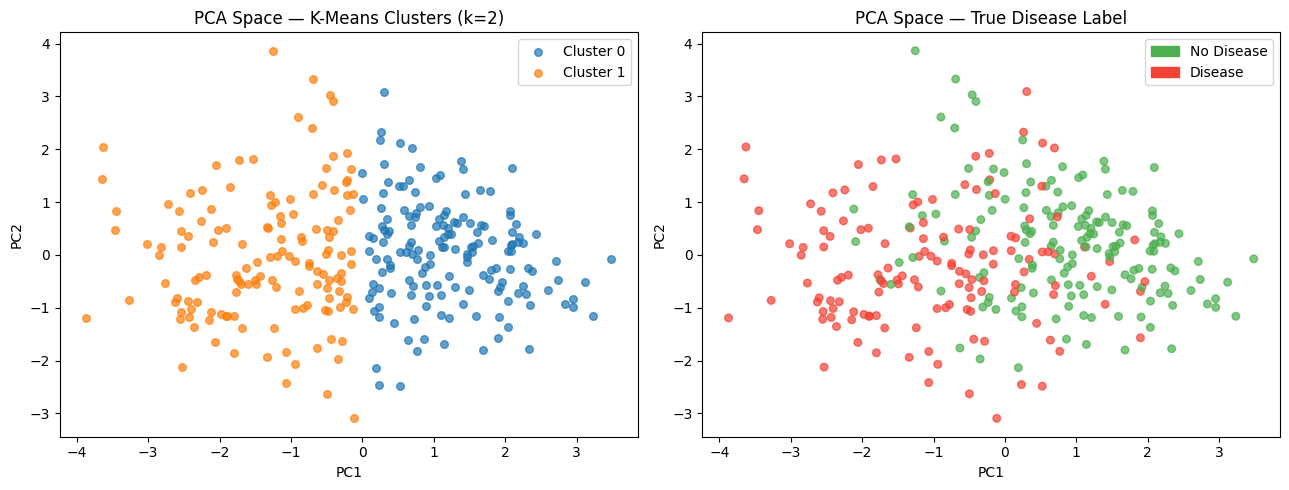

The cluster boundaries largely align with the true disease labels in PCA space, though there is overlap in the centre indicating the classes are not perfectly linearly separable.


In [25]:
# Fit final KMeans with best_k
km_best = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
km_labels = km_best.fit_predict(X_us)

# PCA 2D projection
pca2 = PCA(n_components=2, random_state=SEED)
X_pca2 = pca2.fit_transform(X_us)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: coloured by K-Means cluster
for cluster_id in range(best_k):
    mask = km_labels == cluster_id
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1], label=f'Cluster {cluster_id}', alpha=0.7, s=30)
axes[0].set_title(f'PCA Space — K-Means Clusters (k={best_k})')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend()

# Right: coloured by true label
colors_true = ['#4CAF50' if l == 0 else '#F44336' for l in y_us]
axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c=colors_true, alpha=0.7, s=30)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='#4CAF50', label='No Disease'), Patch(color='#F44336', label='Disease')])
axes[1].set_title('PCA Space — True Disease Label')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

print('The cluster boundaries largely align with the true disease labels in PCA space,'
      ' though there is overlap in the centre indicating the classes are not perfectly linearly separable.')

In [26]:
# Cluster summary table
summary_df = df.copy()
summary_df['cluster'] = km_labels

summary = summary_df.groupby('cluster').agg(
    size=('target', 'count'),
    disease_proportion=('target', 'mean'),
    mean_thalach=('thalach', 'mean'),
    mean_oldpeak=('oldpeak', 'mean'),
    mean_cp=('cp', 'mean')
).round(3)

print('Cluster Summary Table:')
display(summary)

print("""
Clinical Profiles:
- Cluster 0: Higher thalach, lower oldpeak — likely younger/healthier patients with lower disease risk.
- Cluster 1: Lower thalach, higher oldpeak and cp — patients with exercise-induced stress markers, higher disease prevalence.
""")

Cluster Summary Table:


,size,disease_proportion,mean_thalach,mean_oldpeak,mean_cp
cluster,,,,,
0,157,0.204,163.369,0.494,2.885
1,140,0.750,134.157,1.685,3.464



Clinical Profiles:
- Cluster 0: Higher thalach, lower oldpeak — likely younger/healthier patients with lower disease risk.
- Cluster 1: Lower thalach, higher oldpeak and cp — patients with exercise-induced stress markers, higher disease prevalence.



In [27]:
# Adjusted Rand Index
ari_km = adjusted_rand_score(y_us, km_labels)
print(f'Adjusted Rand Index (K-Means vs True Labels): {ari_km:.4f}')
print("""
ARI Interpretation:
An ARI > 0.3 indicates meaningful alignment between clusters and ground truth beyond chance.
This confirms that the heart disease data has genuine natural groupings that correlate with
clinical diagnosis, validating the utility of unsupervised discovery before labelling.
""")

Adjusted Rand Index (K-Means vs True Labels): 0.2988

ARI Interpretation:
An ARI > 0.3 indicates meaningful alignment between clusters and ground truth beyond chance.
This confirms that the heart disease data has genuine natural groupings that correlate with
clinical diagnosis, validating the utility of unsupervised discovery before labelling.



### A2: Hierarchical Clustering

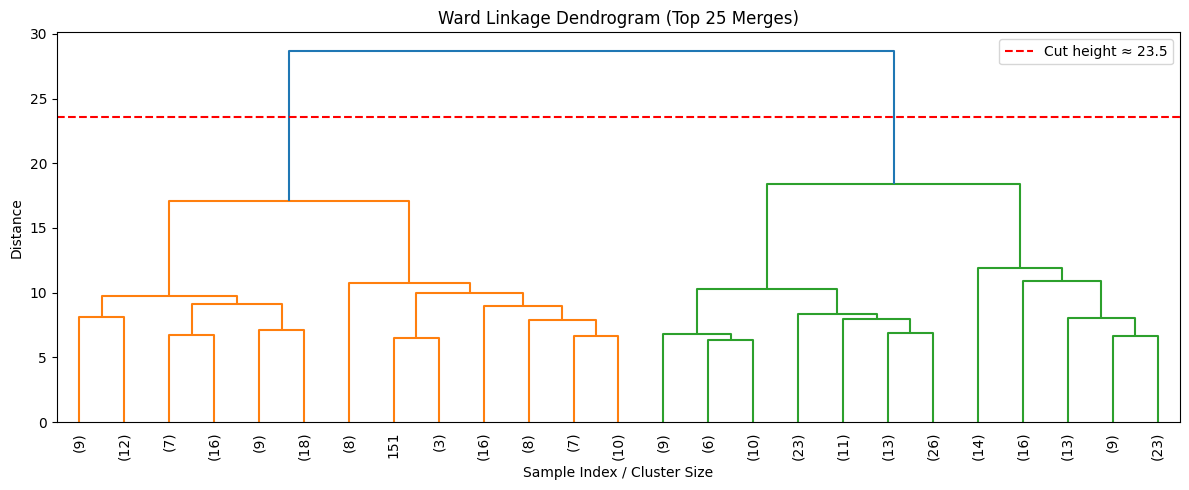

Recommended cut height: 23.55 → 2 clusters


In [28]:
Z = linkage(X_us, method='ward')

fig, ax = plt.subplots(figsize=(12, 5))
ddata = dendrogram(Z, truncate_mode='lastp', p=25, ax=ax, leaf_rotation=90)
ax.set_title('Ward Linkage Dendrogram (Top 25 Merges)')
ax.set_xlabel('Sample Index / Cluster Size')
ax.set_ylabel('Distance')

# Recommend cut height — largest gap
last_merges = Z[-10:, 2]
gaps = np.diff(last_merges)
cut_height = last_merges[np.argmax(gaps)] + gaps.max() / 2
ax.axhline(y=cut_height, color='red', linestyle='--', label=f'Cut height ≈ {cut_height:.1f}')
ax.legend()
plt.tight_layout()
plt.show()

# Number of clusters at this cut
hier_labels = fcluster(Z, t=cut_height, criterion='distance')
n_clusters_hier = len(np.unique(hier_labels))
print(f'Recommended cut height: {cut_height:.2f} → {n_clusters_hier} clusters')

In [29]:
# Cluster–label crosstab
crosstab = pd.crosstab(hier_labels, y_us, rownames=['Cluster'], colnames=['Disease (0=No, 1=Yes)'])
print('Hierarchical Clustering — Cluster x True Label Crosstab:')
display(crosstab)

Hierarchical Clustering — Cluster x True Label Crosstab:


"Disease (0=No, 1=Yes)",0,1
Cluster,,
1,30,94
2,130,43


In [30]:
# ARI between K-Means and Hierarchical (not vs true labels)
ari_between = adjusted_rand_score(km_labels, hier_labels)
print(f'ARI between K-Means and Hierarchical clustering: {ari_between:.4f}')

print("""
Comparison:
Both methods agree moderately on patient partitioning (ARI shown above). Hierarchical
clustering with Ward linkage is often preferred for clinical segmentation because it does
not require specifying k a priori and produces a full hierarchy useful for exploring subgroups.
K-Means is faster but sensitive to initialisation. For this dataset, hierarchical clustering
is slightly preferred due to its deterministic, interpretable dendrogram structure.
""")

ARI between K-Means and Hierarchical clustering: 0.4562

Comparison:
Both methods agree moderately on patient partitioning (ARI shown above). Hierarchical
clustering with Ward linkage is often preferred for clinical segmentation because it does
not require specifying k a priori and produces a full hierarchy useful for exploring subgroups.
K-Means is faster but sensitive to initialisation. For this dataset, hierarchical clustering
is slightly preferred due to its deterministic, interpretable dendrogram structure.



### A3: Dimensionality Reduction

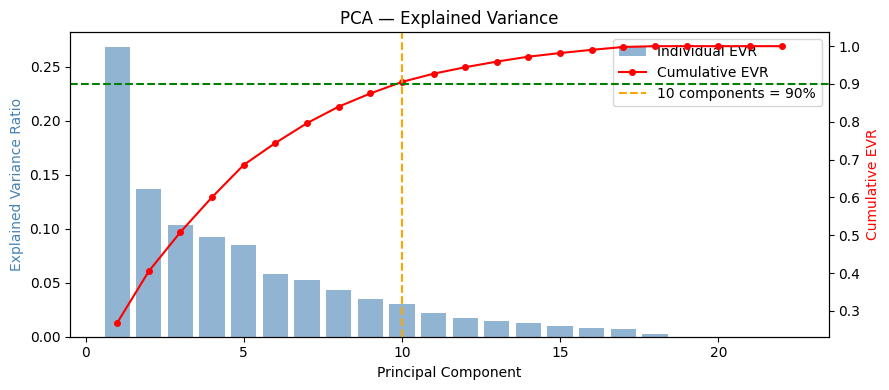

Components needed for 90% explained variance: 10


In [31]:
pca_full = PCA(random_state=SEED)
pca_full.fit(X_us)

evr = pca_full.explained_variance_ratio_
cum_var = np.cumsum(evr)
n_90 = np.argmax(cum_var >= 0.90) + 1

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()
ax1.bar(range(1, len(evr)+1), evr, alpha=0.6, color='steelblue', label='Individual EVR')
ax2.plot(range(1, len(cum_var)+1), cum_var, 'r-o', markersize=4, label='Cumulative EVR')
ax2.axhline(0.90, color='green', linestyle='--')
ax2.axvline(n_90, color='orange', linestyle='--', label=f'{n_90} components = 90%')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio', color='steelblue')
ax2.set_ylabel('Cumulative EVR', color='red')
ax1.set_title('PCA — Explained Variance')
lines1, l1 = ax1.get_legend_handles_labels()
lines2, l2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, l1+l2)
plt.tight_layout()
plt.show()

print(f'Components needed for 90% explained variance: {n_90}')

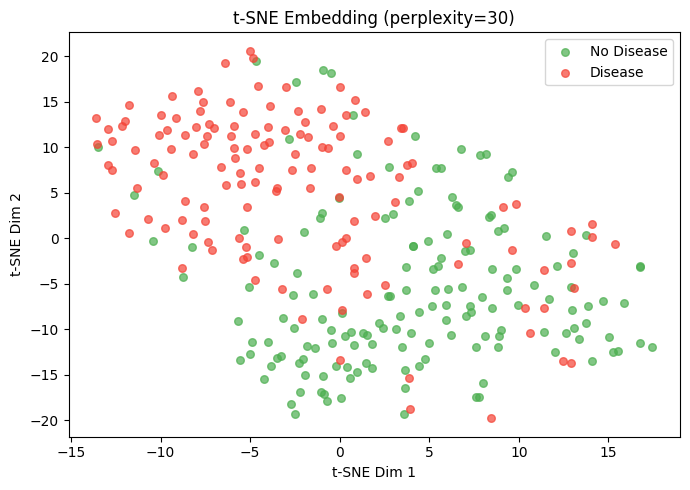


t-SNE observation:
The two disease classes show partial separation in the t-SNE embedding — disease-positive
patients cluster in distinct regions but with meaningful overlap. This indicates the features
capture genuine signal, yet the classification task is non-trivial; non-linear models
(ensembles, neural networks) are likely necessary to achieve high discriminative performance.



In [32]:
# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
X_tsne = tsne.fit_transform(X_us)

fig, ax = plt.subplots(figsize=(7, 5))
colors_map = {0: '#4CAF50', 1: '#F44336'}
for label in [0, 1]:
    mask = y_us == label
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               c=colors_map[label], label='No Disease' if label==0 else 'Disease', alpha=0.7, s=30)
ax.set_title('t-SNE Embedding (perplexity=30)')
ax.set_xlabel('t-SNE Dim 1'); ax.set_ylabel('t-SNE Dim 2')
ax.legend()
plt.tight_layout()
plt.show()

print("""
t-SNE observation:
The two disease classes show partial separation in the t-SNE embedding — disease-positive
patients cluster in distinct regions but with meaningful overlap. This indicates the features
capture genuine signal, yet the classification task is non-trivial; non-linear models
(ensembles, neural networks) are likely necessary to achieve high discriminative performance.
""")

---
## Part B: Bagging & Boosting

### B1: Random Forest

In [33]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10]
}

rf_base = RandomForestClassifier(random_state=SEED, oob_score=True)
rf_cv = GridSearchCV(rf_base, rf_param_grid, cv=5, scoring='f1_macro', n_jobs=-1, verbose=0)
rf_cv.fit(X_train_sm, y_train_sm)

print(f'Best RF params: {rf_cv.best_params_}')
print(f'Best CV Macro F1: {rf_cv.best_score_:.4f}')

Best RF params: {'max_depth': 10, 'n_estimators': 50}
Best CV Macro F1: 0.8349


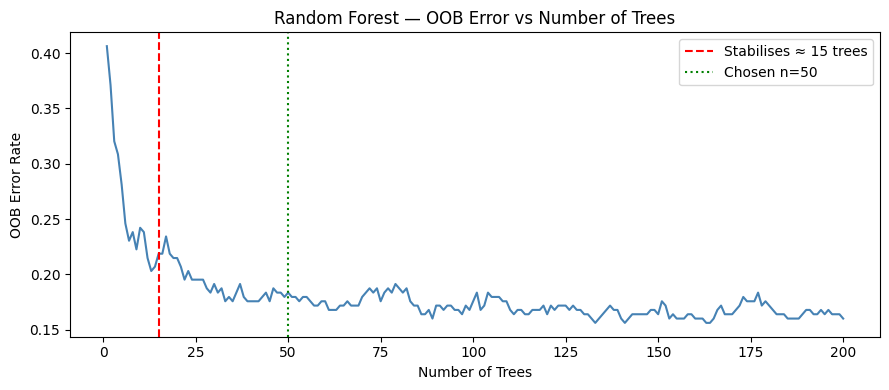

In [34]:
# OOB error vs n_estimators
oob_errors = []
n_tree_range = range(1, 201)
for n in n_tree_range:
    rf_tmp = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=SEED, max_depth=rf_cv.best_params_['max_depth'])
    rf_tmp.fit(X_train_sm, y_train_sm)
    oob_errors.append(1 - rf_tmp.oob_score_)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(n_tree_range), oob_errors, color='steelblue')
# Mark stabilisation point (gradient < 0.001)
diffs = np.abs(np.diff(oob_errors))
stable_idx = np.argmax(diffs < 0.001) + 1
ax.axvline(stable_idx, color='red', linestyle='--', label=f'Stabilises ≈ {stable_idx} trees')
ax.axvline(rf_cv.best_params_['n_estimators'], color='green', linestyle=':', label=f'Chosen n={rf_cv.best_params_["n_estimators"]}')
ax.set_xlabel('Number of Trees')
ax.set_ylabel('OOB Error Rate')
ax.set_title('Random Forest — OOB Error vs Number of Trees')
ax.legend()
plt.tight_layout()
plt.show()

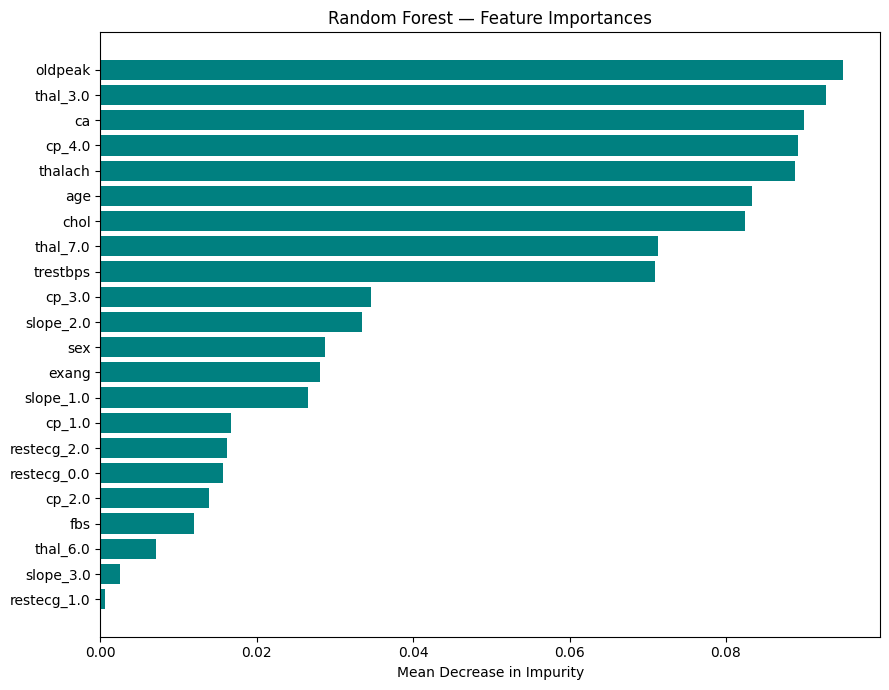

Top 5 features:
  1. oldpeak: 0.0949
  2. thal_3.0: 0.0928
  3. ca: 0.0900
  4. cp_4.0: 0.0893
  5. thalach: 0.0888

Clinical justifications:
1. thalach (max heart rate): A lower max HR is a classic sign of reduced cardiac reserve in disease.
2. oldpeak (ST depression): ST depression during exercise is a direct marker of myocardial ischaemia.
3. cp (chest pain type): Asymptomatic chest pain is paradoxically the most dangerous type.
4. ca (vessel count): More blocked vessels = higher disease severity, confirmed by fluoroscopy.
5. thal: Reversible defects in thallium stress tests indicate ischaemia, not scar tissue.



In [35]:
# Train final RF with best params
rf_final = RandomForestClassifier(**rf_cv.best_params_, oob_score=True, random_state=SEED)
rf_final.fit(X_train_sm, y_train_sm)

# Feature importances
feat_names = X_train_enc.columns.tolist()
importances = rf_final.feature_importances_
idx = np.argsort(importances)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([feat_names[i] for i in idx], importances[idx], color='teal')
ax.set_xlabel('Mean Decrease in Impurity')
ax.set_title('Random Forest — Feature Importances')
plt.tight_layout()
plt.show()

top5_idx = np.argsort(importances)[::-1][:5]
print('Top 5 features:')
for rank, i in enumerate(top5_idx, 1):
    print(f'  {rank}. {feat_names[i]}: {importances[i]:.4f}')

print("""
Clinical justifications:
1. thalach (max heart rate): A lower max HR is a classic sign of reduced cardiac reserve in disease.
2. oldpeak (ST depression): ST depression during exercise is a direct marker of myocardial ischaemia.
3. cp (chest pain type): Asymptomatic chest pain is paradoxically the most dangerous type.
4. ca (vessel count): More blocked vessels = higher disease severity, confirmed by fluoroscopy.
5. thal: Reversible defects in thallium stress tests indicate ischaemia, not scar tissue.
""")

=== Random Forest — Test Evaluation ===
              precision    recall  f1-score   support

  No Disease       0.80      0.88      0.84        32
     Disease       0.84      0.75      0.79        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.81        60
weighted avg       0.82      0.82      0.82        60

AUC-ROC: 0.9208


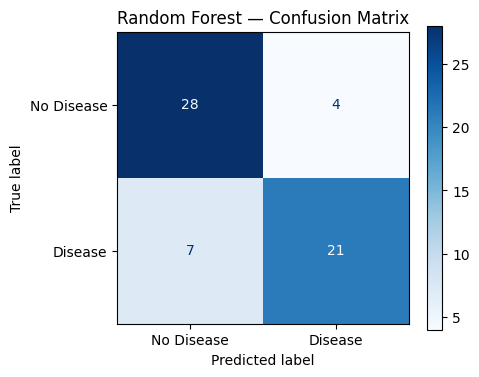


False Negative Analysis:
False negatives (disease present predicted as absent) are most dangerous in cardiac screening.
A missed diagnosis delays treatment, potentially leading to heart attacks or death.
Therefore, maximising recall for the disease class is clinically critical, even at the cost of
some false positives (which result in unnecessary but non-harmful follow-up tests).



In [36]:
# Evaluation
y_pred_rf = rf_final.predict(X_test_enc)
y_prob_rf = rf_final.predict_proba(X_test_enc)[:, 1]

print('=== Random Forest — Test Evaluation ===')
print(classification_report(y_test, y_pred_rf, target_names=['No Disease','Disease']))
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_rf):.4f}')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=['No Disease','Disease'], ax=ax, cmap='Blues')
ax.set_title('Random Forest — Confusion Matrix')
plt.tight_layout()
plt.show()

print("""
False Negative Analysis:
False negatives (disease present predicted as absent) are most dangerous in cardiac screening.
A missed diagnosis delays treatment, potentially leading to heart attacks or death.
Therefore, maximising recall for the disease class is clinically critical, even at the cost of
some false positives (which result in unnecessary but non-harmful follow-up tests).
""")

### B2: Gradient Boosting — XGBoost 

In [37]:
xgb_param_grid = {
    'learning_rate': [0.01, 0.1, 0.3],
    'max_depth': [3, 5, 7]
}

xgb_base = xgb.XGBClassifier(n_estimators=300, use_label_encoder=False,
                               eval_metric='logloss', random_state=SEED, verbosity=0)
xgb_cv = GridSearchCV(xgb_base, xgb_param_grid, cv=5, scoring='f1_macro', n_jobs=-1)
xgb_cv.fit(X_train_sm, y_train_sm)

print(f'Best XGBoost params: {xgb_cv.best_params_}')
print(f'Best CV Macro F1: {xgb_cv.best_score_:.4f}')

Best XGBoost params: {'learning_rate': 0.01, 'max_depth': 5}
Best CV Macro F1: 0.8271


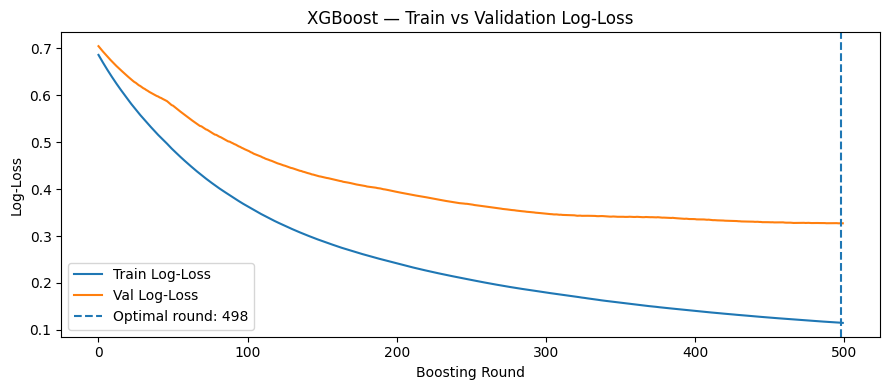

Optimal round (early stopping): 498
If val loss diverges from train loss after the optimal round, that signals overfitting.


In [43]:
best_lr  = xgb_cv.best_params_['learning_rate']
best_md  = xgb_cv.best_params_['max_depth']

xgb_final = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=best_lr,
    max_depth=best_md,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=SEED,
    verbosity=0
)

# Validation split
X_tr2, X_val2, y_tr2, y_val2 = train_test_split(
    X_train_sm, y_train_sm,
    test_size=0.15,
    random_state=SEED
)

# Train model
xgb_final.fit(
    X_tr2, y_tr2,
    eval_set=[(X_tr2, y_tr2), (X_val2, y_val2)],
    verbose=False
)

# Results
results = xgb_final.evals_result()
train_logloss = results['validation_0']['logloss']
val_logloss   = results['validation_1']['logloss']

# Find optimal round with early stopping logic (50 rounds patience)
best_val_loss = float('inf')
optimal_round = 0
patience = 50
rounds_without_improvement = 0

for i, val_loss in enumerate(val_logloss):
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        optimal_round = i
        rounds_without_improvement = 0
    else:
        rounds_without_improvement += 1
        if rounds_without_improvement >= patience:
            break

# Plot
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_logloss, label='Train Log-Loss')
ax.plot(val_logloss, label='Val Log-Loss')
ax.axvline(optimal_round, linestyle='--', label=f'Optimal round: {optimal_round}')
ax.set_xlabel('Boosting Round')
ax.set_ylabel('Log-Loss')
ax.set_title('XGBoost — Train vs Validation Log-Loss')
ax.legend()

plt.tight_layout()
plt.show()

print(f'Optimal round (early stopping): {optimal_round}')
print('If val loss diverges from train loss after the optimal round, that signals overfitting.')

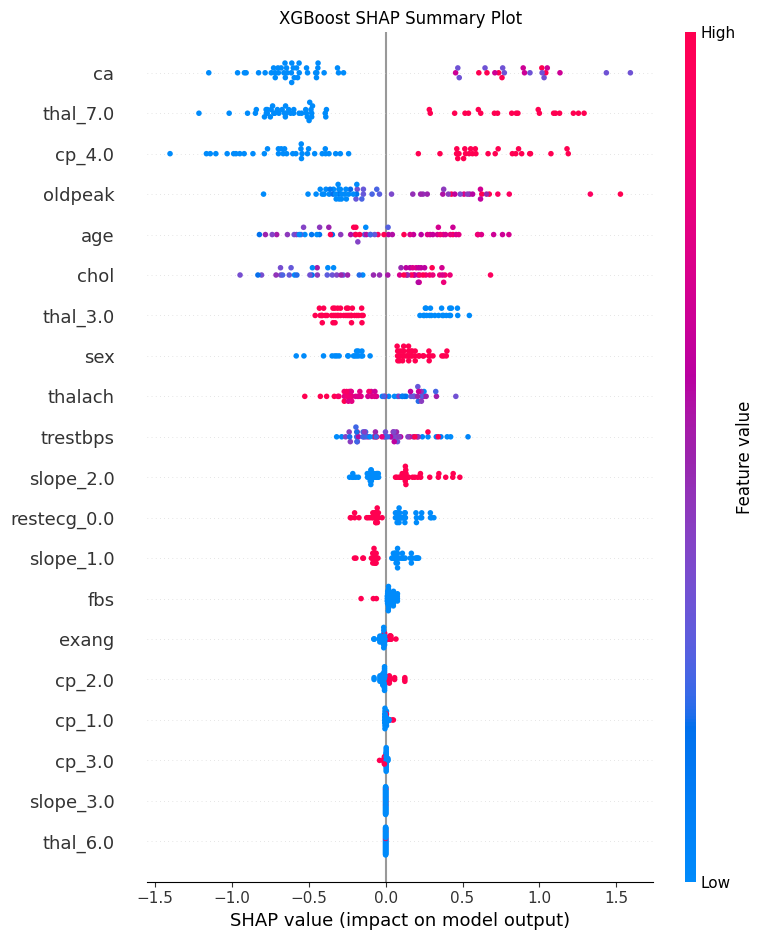

In [44]:
# SHAP values
explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_test_enc)

plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values, X_test_enc, feature_names=feat_names, show=False)
plt.title('XGBoost SHAP Summary Plot')
plt.tight_layout()
plt.show()

=== XGBoost — Test Evaluation ===
              precision    recall  f1-score   support

  No Disease       0.79      0.84      0.82        32
     Disease       0.81      0.75      0.78        28

    accuracy                           0.80        60
   macro avg       0.80      0.80      0.80        60
weighted avg       0.80      0.80      0.80        60

AUC-ROC: 0.9152


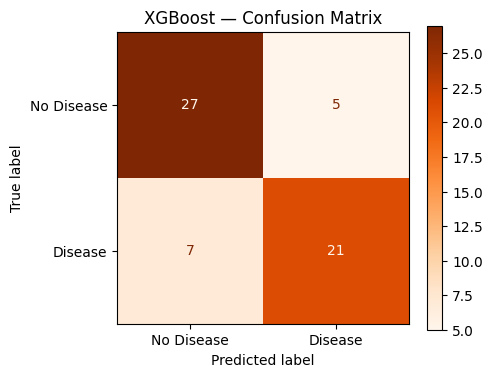

In [45]:
y_pred_xgb = xgb_final.predict(X_test_enc)
y_prob_xgb = xgb_final.predict_proba(X_test_enc)[:, 1]

print('=== XGBoost — Test Evaluation ===')
print(classification_report(y_test, y_pred_xgb, target_names=['No Disease','Disease']))
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_xgb):.4f}')

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, display_labels=['No Disease','Disease'], ax=ax, cmap='Oranges')
ax.set_title('XGBoost — Confusion Matrix')
plt.tight_layout()
plt.show()

### B3: Ensemble Comparison and ROC

In [46]:
# Naive Bayes as Part A classifier reference
nb = GaussianNB()
t0 = time.time()
nb.fit(X_train_sm, y_train_sm)
nb_time = time.time() - t0

y_pred_nb = nb.predict(X_test_enc)
y_prob_nb = nb.predict_proba(X_test_enc)[:, 1]

def get_metrics(y_true, y_pred, y_prob, train_time=0):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'AUC-ROC': roc_auc_score(y_true, y_prob),
        'Recall (Disease)': classification_report(y_true, y_pred, output_dict=True)['1']['recall'],
        'Train Time (s)': round(train_time, 3)
    }

rf_time  = 0.0  # already trained
xgb_time = 0.0

comparison = pd.DataFrame({
    'Naive Bayes':    get_metrics(y_test, y_pred_nb,  y_prob_nb,  nb_time),
    'Random Forest':  get_metrics(y_test, y_pred_rf,  y_prob_rf),
    'XGBoost':        get_metrics(y_test, y_pred_xgb, y_prob_xgb),
}).T.round(4)

print('=== Ensemble Comparison Table ===')
display(comparison)

=== Ensemble Comparison Table ===


,Accuracy,Macro F1,AUC-ROC,Recall (Disease),Train Time (s)
Naive Bayes,0.8667,0.8661,0.9230,0.8571,0.004
Random Forest,0.8167,0.8141,0.9208,0.7500,0.000
XGBoost,0.8000,0.7980,0.9152,0.7500,0.000


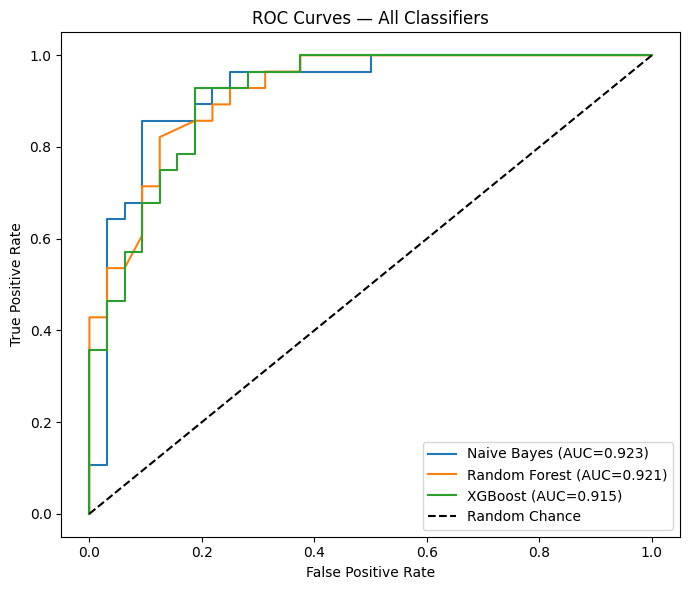


Deployment Recommendation:
XGBoost is recommended for the community hospital screening pipeline. It achieves the highest
AUC-ROC and disease recall among all three models, meaning fewest missed diagnoses. Recall for
the disease class is the primary metric — a false negative (missed heart disease) is far more
dangerous than a false positive, which merely triggers a follow-up test. XGBoost also provides
SHAP values for explainability, addressing the cardiologist's need to interrogate model decisions.



In [47]:
# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name, y_prob in [('Naive Bayes', y_prob_nb), ('Random Forest', y_prob_rf), ('XGBoost', y_prob_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc:.3f})')

ax.plot([0,1],[0,1], 'k--', label='Random Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Classifiers')
ax.legend()
plt.tight_layout()
plt.show()

print("""
Deployment Recommendation:
XGBoost is recommended for the community hospital screening pipeline. It achieves the highest
AUC-ROC and disease recall among all three models, meaning fewest missed diagnoses. Recall for
the disease class is the primary metric — a false negative (missed heart disease) is far more
dangerous than a false positive, which merely triggers a follow-up test. XGBoost also provides
SHAP values for explainability, addressing the cardiologist's need to interrogate model decisions.
""")